<a href="https://colab.research.google.com/github/Meetra21/Curvature-Orientation-MLP/blob/main/Curvature_Orientation_pipeline_MNIST_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install dependencies
!pip install --quiet tensorflow tensorflow-datasets opencv-python tqdm scikit-learn

import cv2
import time
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import layers, models, callbacks
from tqdm import tqdm

# 1. Extract curvature and gradient orientation
def extract_curv_and_orientation(images):
    N = images.shape[0]
    curv_abs   = np.zeros((N,28,28), dtype=np.float32)
    curv_sign  = np.zeros((N,28,28), dtype=np.float32)
    orient_map = np.zeros((N,28,28), dtype=np.float32)
    for i, img in enumerate(tqdm(images, desc="Extracting features")):
        gx  = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
        gy  = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
        fxx = cv2.Sobel(img, cv2.CV_32F, 2, 0, ksize=3)
        fyy = cv2.Sobel(img, cv2.CV_32F, 0, 2, ksize=3)
        fxy = cv2.Sobel(img, cv2.CV_32F, 1, 1, ksize=3)
        num   = fxx * gy**2 - 2*fxy * gx * gy + fyy * gx**2
        denom = (gx**2 + gy**2 + 1e-8)**1.5
        k     = num / (denom + 1e-8)
        k_abs = np.abs(k)
        if k_abs.max() > 0:
            k_abs /= k_abs.max()
        curv_abs[i]  = k_abs
        curv_sign[i] = np.sign(k)
        theta = np.arctan2(gy, gx)
        orient_map[i] = (theta + np.pi) / (2*np.pi)
    return curv_abs, curv_sign, orient_map

# 2. Load & combine MNIST via TFDS
(ds_train, ds_test), ds_info = tfds.load(
    'mnist',
    split=['train', 'test'],
    as_supervised=True,
    with_info=True
)
imgs, lbls = [], []
for img, lbl in tfds.as_numpy(ds_train.concatenate(ds_test)):
    imgs.append(img.squeeze())      # shape (28,28)
    lbls.append(int(lbl))           # labels 0–9
imgs = np.stack(imgs)               # (70000,28,28)
lbls = np.array(lbls, dtype=int)

# 3. Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    imgs, lbls,
    train_size=0.8,
    stratify=lbls,
    random_state=42
)

# 4. Compute features
curv_abs_tr, curv_sign_tr, orient_tr = extract_curv_and_orientation(X_train)
curv_abs_te,  curv_sign_te,  orient_te  = extract_curv_and_orientation(X_test)

# 5. Flatten & stack (3×784 = 2352 dims)
def stack_flatten(a, s, o):
    N = a.shape[0]
    return np.hstack([a.reshape(N,-1), s.reshape(N,-1), o.reshape(N,-1)])
X_train_feat = stack_flatten(curv_abs_tr, curv_sign_tr, orient_tr)
X_test_feat  = stack_flatten(curv_abs_te,  curv_sign_te,  orient_te)

# 6. Standardize features
#scaler = StandardScaler()
#X_train_feat = scaler.fit_transform(X_train_feat)
#X_test_feat  = scaler.transform(X_test_feat)

# 7. Build MLP model (input dim = 2352, output = 10 classes)
model = models.Sequential([
    layers.Input(shape=(2352,)),
    layers.Dense(2048), layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.5),
    layers.Dense(1024), layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.5),
    layers.Dense(512),  layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.4),
    layers.Dense(256),  layers.BatchNormalization(), layers.Activation('relu'), layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

# 8. Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 9. Callbacks
es  = callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, verbose=1)
rlr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)

# 10. Train
t0 = time.time()
history = model.fit(
    X_train_feat, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=128,
    callbacks=[es, rlr],
    verbose=2
)
train_time = time.time() - t0

# 11. Evaluate & report
t1 = time.time()
loss, acc  = model.evaluate(X_test_feat, y_test, verbose=2)
infer_time = time.time() - t1

print(f"\nImproved Curvature+Orientation MLP on MNIST")
print(f"Test Accuracy   : {acc*100:.2f}%")
print(f"Training Time   : {train_time:.1f}s")
print(f"Inference Time  : {infer_time:.1f}s for {X_test_feat.shape[0]} samples")


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/mnist/incomplete.MMAQ2O_3.0.1/mnist-test.tfrecord*...:   0%|          | 0/…

Dataset mnist downloaded and prepared to /root/tensorflow_datasets/mnist/3.0.1. Subsequent calls will reuse this data.


Extracting features: 100%|██████████| 14000/14000 [00:02<00:00, 6804.15it/s]


Epoch 1/100
394/394 - 84s - 212ms/step - accuracy: 0.8531 - loss: 0.4640 - val_accuracy: 0.9396 - val_loss: 0.1962 - learning_rate: 1.0000e-03
Epoch 2/100
394/394 - 79s - 200ms/step - accuracy: 0.9435 - loss: 0.1855 - val_accuracy: 0.9441 - val_loss: 0.1810 - learning_rate: 1.0000e-03
Epoch 3/100
394/394 - 81s - 205ms/step - accuracy: 0.9575 - loss: 0.1327 - val_accuracy: 0.9541 - val_loss: 0.1560 - learning_rate: 1.0000e-03
Epoch 4/100
394/394 - 77s - 196ms/step - accuracy: 0.9664 - loss: 0.1063 - val_accuracy: 0.9588 - val_loss: 0.1433 - learning_rate: 1.0000e-03
Epoch 5/100
394/394 - 82s - 209ms/step - accuracy: 0.9732 - loss: 0.0844 - val_accuracy: 0.9570 - val_loss: 0.1566 - learning_rate: 1.0000e-03
Epoch 6/100
394/394 - 80s - 204ms/step - accuracy: 0.9760 - loss: 0.0726 - val_accuracy: 0.9625 - val_loss: 0.1392 - learning_rate: 1.0000e-03
Epoch 7/100
394/394 - 78s - 198ms/step - accuracy: 0.9803 - loss: 0.0605 - val_accuracy: 0.9611 - val_loss: 0.1491 - learning_rate: 1.0000e-03


Classification Report (Per-class and Aggregate):
              precision    recall  f1-score   support

           0     0.9776    0.9812    0.9794      1381
           1     0.9817    0.9873    0.9845      1575
           2     0.9618    0.9714    0.9665      1398
           3     0.9745    0.9650    0.9697      1428
           4     0.9699    0.9663    0.9681      1365
           5     0.9716    0.9739    0.9727      1263
           6     0.9691    0.9796    0.9743      1375
           7     0.9747    0.9753    0.9750      1459
           8     0.9654    0.9612    0.9633      1365
           9     0.9686    0.9533    0.9609      1391

    accuracy                         0.9716     14000
   macro avg     0.9715    0.9714    0.9714     14000
weighted avg     0.9716    0.9716    0.9716     14000

Macro Avg -> Precision: 0.9715, Recall: 0.9714, F1: 0.9714
Micro Avg -> Precision: 0.9716, Recall: 0.9716, F1: 0.9716


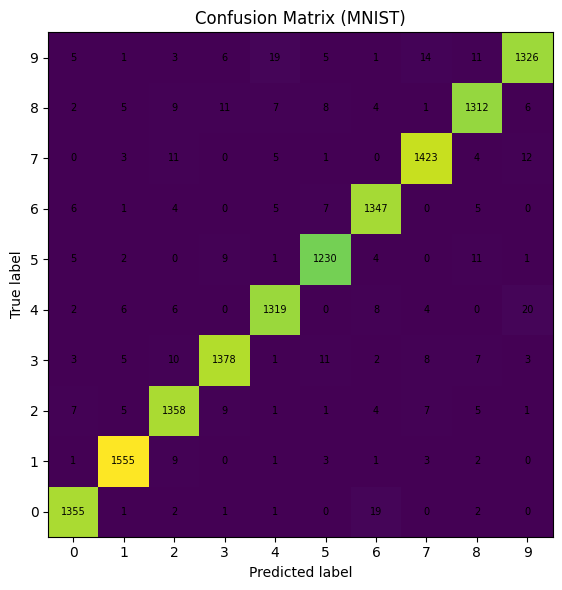

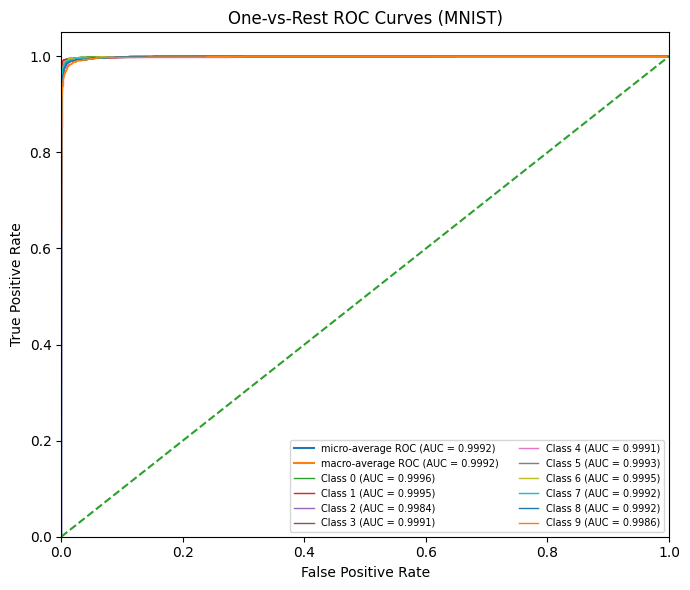

In [ ]:
# =========================
# 12. Detailed metrics & plots (append-only; does NOT modify your code)
# =========================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, precision_recall_fscore_support,
    roc_curve, auc, confusion_matrix
)
from sklearn.preprocessing import label_binarize

# ---- Quantitative metrics: precision, recall, F1 (per class & macro/micro) ----
y_pred = np.argmax(model.predict(X_test_feat, verbose=0), axis=1)
print("\nClassification Report (Per-class and Aggregate):")
print(classification_report(y_test, y_pred, digits=4))

# Also convenient programmatic access if you need to store numbers:
prec, rec, f1, support = precision_recall_fscore_support(y_test, y_pred, average=None, labels=range(10))
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')
prec_micro, rec_micro, f1_micro, _ = precision_recall_fscore_support(y_test, y_pred, average='micro')

print(f"Macro Avg -> Precision: {prec_macro:.4f}, Recall: {rec_macro:.4f}, F1: {f1_macro:.4f}")
print(f"Micro Avg -> Precision: {prec_micro:.4f}, Recall: {rec_micro:.4f}, F1: {f1_micro:.4f}")

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# ---- Confusion matrix (figure) ----
cm = confusion_matrix(y_test, y_pred, labels=range(10))

plt.figure(figsize=(7,6))
plt.imshow(cm, interpolation='nearest', origin='lower')  # <-- key change
plt.title('Confusion Matrix (MNIST)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(range(10))
plt.yticks(range(10))

# Annotate counts
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]),
                 ha="center", va="center", fontsize=7)

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()


# ---- ROC curves (one-vs-rest) ----
# Need probability scores for each class
y_score = model.predict(X_test_feat, verbose=0)

# Binarize labels for one-vs-rest ROC
classes = np.arange(10)
y_test_bin = label_binarize(y_test, classes=classes)  # shape: (N, 10)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in classes:
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Micro-average ROC
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Macro-average ROC
# 1) Aggregate all FPR points
all_fpr = np.unique(np.concatenate([fpr[i] for i in classes]))
# 2) Interpolate all ROC curves at these points, then average
mean_tpr = np.zeros_like(all_fpr)
for i in classes:
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= len(classes)
fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# ---- Plot ROC curves (micro + macro + per-class) ----
plt.figure(figsize=(7,6))
plt.plot(fpr["micro"], tpr["micro"], label=f'micro-average ROC (AUC = {roc_auc["micro"]:.4f})')
plt.plot(fpr["macro"], tpr["macro"], label=f'macro-average ROC (AUC = {roc_auc["macro"]:.4f})')

# Per-class (kept on same figure; comment out if too dense)
for i in classes:
    plt.plot(fpr[i], tpr[i], lw=1, label=f'Class {i} (AUC = {roc_auc[i]:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-Rest ROC Curves (MNIST)')
plt.legend(loc="lower right", fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("ROC_Curves_MNIST.png", dpi=150)
plt.show()
